# PSO for TSP: comparing results and run times

This notebook compares every PSO variant in `results/` on two measures:

* **Quality**: gap to the published TSPLIB optimum, $\text{gap} = (L_{best} - L_{opt}) / L_{opt} \cdot 100\%$, and improvement over the greedy start tour.
* **Cost**: wall time per run, iterations until early stop, and time per iteration.

Run results are pooled per *configuration* = (instance, algorithm name, topology parameter).
Some files were produced before last week's bug fixes, so they are filtered out first (section 1).

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as ss
import scikit_posthocs as sp

pd.set_option("display.precision", 2)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RESULTS = ROOT / "results"

# Published TSPLIB optima (the JSONs store optimal_known = null).
OPTIMA = {"berlin52": 7542, "bier127": 118282, "a280": 2579,
          "ali535": 202339, "gr666": 294358, "pr1002": 259045}
PROBLEMS = sorted(OPTIMA, key=lambda p: int("".join(filter(str.isdigit, p))))
GEO = {"ali535", "gr666"}

OPERATOR = {"default": "PSO", "cognitive": "PSO-Cognitive", "apv": "PSO-APV", "swu": "PSO-SWU"}
TOPOLOGY = {"global": "Global", "ring": "Ring", "tree": "Tree", "mesh": "Mesh", "torus": "Torus",
            "freescale": "FreeScale", "dynsim": "DynSim", "dynopp": "DynOpp", "dynmix": "DynMix"}
STATIC = ["Ring", "Tree", "Mesh", "Torus", "FreeScale"]
DYNAMIC = ["DynSim", "DynOpp", "DynMix"]
FAMILIES = ["PSO", "PSO-Cognitive", "PSO-Explore", "PSO-Cognitive-Explore", "PSO-APV", "PSO-SWU"]

## 1. Loading the data and dropping invalid runs

Each JSON file holds N repetitions of one configuration. Runs are excluded when the code that produced them was later found to be wrong:

| Reason | Rule |
|---|---|
| APV/SWU before fix `38e0dcb` | APV/SWU file without a `v_explore` parameter: the operator just returned its greedy input |
| Explore before fix `0b2f1e5` | Explore file without an explicit `stagnation_trigger`: mutation wasn't gated, and the cognitive step did nothing |
| GEO distance bug | `ali535` / `gr666` produced before 2026-10-03, which used Euclidean distance on GEO coordinates |
| Non-standard config | anything other than 1000 particles × 30000 iterations |

In [2]:
rows = []
for f in sorted(RESULTS.glob("*.json")):
    d = json.loads(f.read_text())
    alg, cfg = d["algorithm"], d["algorithm"]["config"]
    prob = d["problem"]["instance_name"]
    family = OPERATOR[alg["operator_variant"]]
    if alg["enhancer"] == "explore":
        family += "-Explore"
    topo = TOPOLOGY[alg["topology"]]
    for r in d["runs"]:
        rows.append(dict(
            file=f.name, timestamp=d["timestamp_utc"], problem=prob, dim=d["problem"]["dimension"],
            algorithm=alg["name"], family=family, topology=topo,
            radius=cfg.get("neighbours_radius") if topo in STATIC else np.nan,
            pct=cfg.get("neighbor_pct", np.nan) if topo in DYNAMIC else np.nan,
            v_explore=cfg.get("v_explore", np.nan), stagnation_trigger=cfg.get("stagnation_trigger", np.nan),
            particles=cfg["num_particles"], max_iter=cfg["max_iter"], file_reps=d["aggregate"]["n_runs"],
            init=r["init_path_length"], best=r["best_path_length"], iterations=r["iterations_run"],
            wall=r["wall_time_seconds"], history=np.asarray(r["iteration_history"]),
        ))
runs = pd.DataFrame(rows)

def invalid_reason(r):
    if r.particles != 1000 or r.max_iter != 30000:
        return "non-standard config"
    if r.family in ("PSO-APV", "PSO-SWU") and np.isnan(r.v_explore):
        return "APV/SWU before fix 38e0dcb"
    if "Explore" in r.family and np.isnan(r.stagnation_trigger):
        return "Explore before fix 0b2f1e5"
    if r.problem in GEO and r.timestamp < "2026-10-03":
        return "GEO distance bug"
    return "valid"

runs["status"] = runs.apply(invalid_reason, axis=1)
summary = (runs.groupby("status")
               .agg(files=("file", "nunique"), runs=("file", "size"))
               .sort_values("runs", ascending=False))
summary

,files,runs
status,,
valid,460,4165
APV/SWU before fix 38e0dcb,351,3510
Explore before fix 0b2f1e5,242,2390
GEO distance bug,103,1030
non-standard config,1,3


In [3]:
runs = runs[runs.status == "valid"].copy()
runs["opt"] = runs.problem.map(OPTIMA)
runs["gap"] = (runs.best - runs.opt) / runs.opt * 100
runs["init_gap"] = (runs.init - runs.opt) / runs.opt * 100
runs["improvement"] = (runs.init - runs.best) / runs.init * 100
runs["sec_per_iter"] = runs.wall / runs.iterations

def param_label(r):
    if r.topology in STATIC:
        return f"r={int(r.radius)}"
    if r.topology in DYNAMIC:
        return f"{r.pct:.0%}"
    if r.family in ("PSO-APV", "PSO-SWU"):
        return f"ve={r.v_explore:g}"
    return ""

runs["param"] = runs.apply(param_label, axis=1)
runs["config"] = (runs.family + " | " + runs.topology + " " + runs.param).str.strip()
runs["problem"] = pd.Categorical(runs.problem, PROBLEMS, ordered=True)

# One row per configuration. Duplicate files of the same config, e.g. re-runs, are pooled.
KEY = ["problem", "family", "topology", "param", "config"]
cfg = (runs.groupby(KEY, observed=True)
           .agg(n=("gap", "size"), gap_median=("gap", "median"), gap_mean=("gap", "mean"),
                gap_std=("gap", "std"), gap_min=("gap", "min"), improvement=("improvement", "median"),
                wall_median=("wall", "median"), iters_median=("iterations", "median"),
                sec_per_iter=("sec_per_iter", "median"))
           .reset_index())
print(f"{len(runs)} valid runs in {len(cfg)} configurations")
pd.crosstab(cfg.problem, cfg.family).reindex(columns=FAMILIES, fill_value=0)

4165 valid runs in 451 configurations


family,PSO,PSO-Cognitive,PSO-Explore,PSO-Cognitive-Explore,PSO-APV,PSO-SWU
problem,,,,,,
berlin52,35,36,22,22,3,3
bier127,37,36,20,20,3,3
a280,36,36,20,15,3,3
ali535,17,16,0,0,0,0
gr666,12,13,0,0,0,0
pr1002,23,17,0,0,0,0


The table above shows **configurations per instance and family**. Coverage isn't even: `PSO` and `PSO-Cognitive` still carry the old full radius sweep (1, 2, 5, 10, 25, 50), the re-run Explore variants use the design-C radii (1, 5, 25), and APV/SWU so far exist only as the opt-in probe on the three small instances.

**Caveat on the gap:** the reader computes EUC_2D distances as unrounded floats, while TSPLIB optima use integer-rounded edges. So a tour that is optimal can show a small positive gap (berlin52's optimal tour is ≈ 7544.4 here against 7542, i.e. 0.03 %). Gaps under about 0.05 % should be read as "optimal".

### Greedy starting point
Every run starts from a greedy-initialised swarm. That start is the baseline any PSO variant has to beat.

In [4]:
runs.groupby("problem", observed=True).agg(
    dim=("dim", "first"), optimum=("opt", "first"),
    greedy_gap_median=("init_gap", "median"), best_gap_overall=("gap", "min"),
    valid_runs=("gap", "size"))

,dim,optimum,greedy_gap_median,best_gap_overall,valid_runs
problem,,,,,
berlin52,52,7542,8.49,0.03,1210
bier127,127,118282,13.26,1.10,1190
a280,280,2579,19.98,4.21,1130
ali535,535,202339,19.02,6.90,165
gr666,666,294358,18.99,9.20,125
pr1002,1002,259045,20.53,14.51,345


## 2. Quality: the best configuration of each family

In [5]:
best_per_family = (cfg.sort_values("gap_median")
                      .groupby(["problem", "family"], observed=True).head(1))
pivot = best_per_family.pivot(index="problem", columns="family", values="gap_median")
pivot = pivot.reindex(columns=[f for f in FAMILIES if f in pivot.columns])
pivot.insert(0, "greedy start", runs.groupby("problem", observed=True).init_gap.median())
print("Median gap to optimum [%] of each family's best configuration")
pivot.style.format("{:.2f}", na_rep="–").background_gradient(axis=1, cmap="RdYlGn_r")

Median gap to optimum [%] of each family's best configuration


family,greedy start,PSO,PSO-Cognitive,PSO-Explore,PSO-Cognitive-Explore,PSO-APV,PSO-SWU
problem,,,,,,,
berlin52,8.49,0.03,0.03,0.03,0.03,7.84,7.82
bier127,13.26,3.68,6.91,4.16,2.42,10.42,7.39
a280,19.98,10.76,17.16,8.42,7.59,19.15,19.47
ali535,19.02,10.52,16.34,–,–,–,–
gr666,18.99,10.53,18.00,–,–,–,–
pr1002,20.53,18.46,20.53,–,–,–,–


In [6]:
print("Which configuration is best per instance (top 5 by median gap)")
(cfg.sort_values(["problem", "gap_median"])
    .groupby("problem", observed=True).head(5)
    [["problem", "config", "n", "gap_median", "gap_min", "gap_std", "improvement", "wall_median"]]
    .rename(columns={"wall_median": "wall_s"})
    .reset_index(drop=True))

Which configuration is best per instance (top 5 by median gap)


,problem,config,n,gap_median,gap_min,gap_std,improvement,wall_s
0,berlin52,PSO | DynMix 25%,10,0.03,0.03,0.00,7.80,310.10
1,berlin52,PSO | DynMix 5%,10,0.03,0.03,3.25,7.80,243.00
2,berlin52,PSO | DynOpp 25%,10,0.03,0.03,0.00,7.80,280.10
3,berlin52,PSO | DynOpp 5%,10,0.03,0.03,0.77,7.80,285.92
4,berlin52,PSO | DynSim 25%,10,0.03,0.03,1.08,7.80,336.77
5,bier127,PSO-Cognitive-Explore | Torus r=1,10,2.42,1.41,0.61,9.58,3919.26
6,bier127,PSO-Cognitive-Explore | Ring r=5,10,2.92,1.11,0.97,9.13,3269.15
7,bier127,PSO-Cognitive-Explore | Ring r=1,10,3.29,1.72,1.35,8.81,5422.06
8,bier127,PSO-Cognitive-Explore | Mesh r=1,10,3.34,2.17,0.75,8.76,2535.15
9,bier127,PSO | Mesh r=5,10,3.68,2.59,1.16,8.46,1487.84


## 3. Topology comparison

For every (family, topology) cell, the heatmap shows the median gap of the **best parameter value** (radius or neighbourhood %). So it compares each topology at its own best tuning.

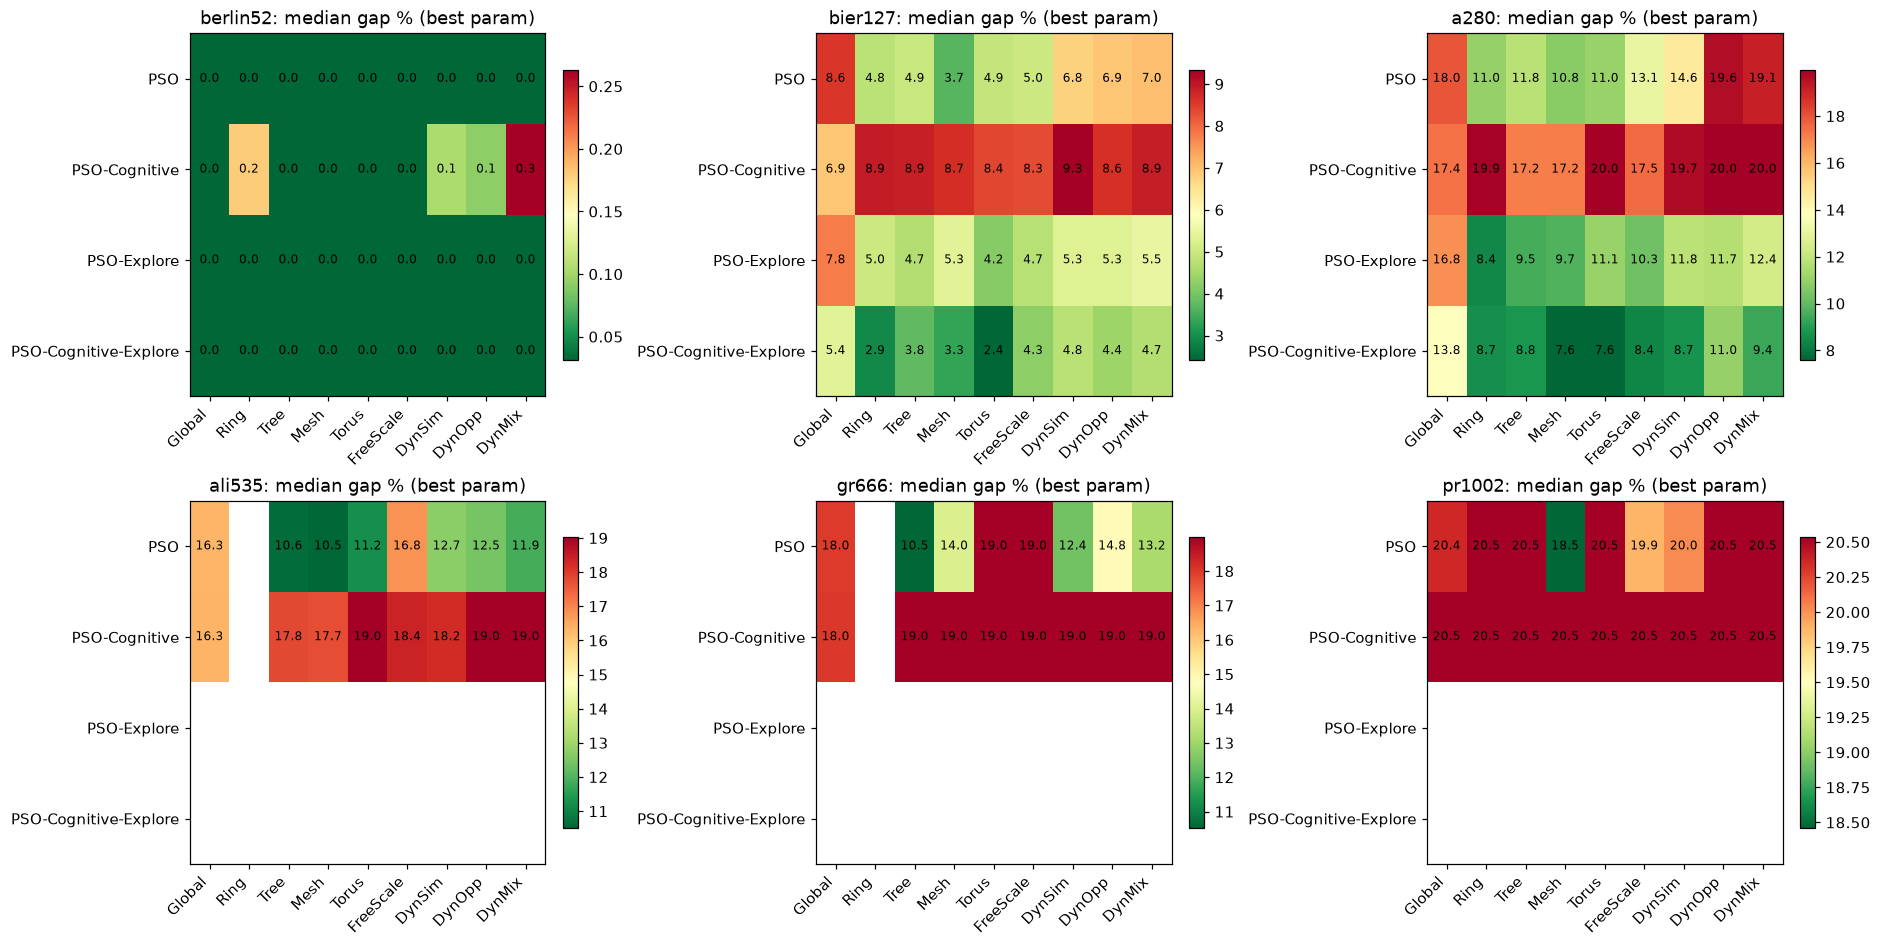

In [7]:
fams = [f for f in FAMILIES if f not in ("PSO-APV", "PSO-SWU")]
topos = ["Global"] + STATIC + DYNAMIC
fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), constrained_layout=True)
for ax, prob in zip(axes.flat, PROBLEMS):
    sub = cfg[(cfg.problem == prob) & cfg.family.isin(fams)]
    m = sub.groupby(["family", "topology"]).gap_median.min().unstack().reindex(index=fams, columns=topos)
    im = ax.imshow(m.values, cmap="RdYlGn_r", aspect="auto")
    ax.set_xticks(range(len(topos)), topos, rotation=45, ha="right")
    ax.set_yticks(range(len(fams)), fams)
    for (i, j), v in np.ndenumerate(m.values):
        if not np.isnan(v):
            ax.text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=8)
    ax.set_title(f"{prob}: median gap % (best param)")
    ax.grid(False)
    fig.colorbar(im, ax=ax, shrink=0.8)
plt.show()

### 3.1 Effect of the neighbourhood radius (static topologies)

At equal radius, topologies have very different neighbourhood **sizes**: Ring has $2r$ neighbours, Mesh/Torus $(2r+1)^2-1$. So the curves below mix "topology" with "how many particles each particle sees".

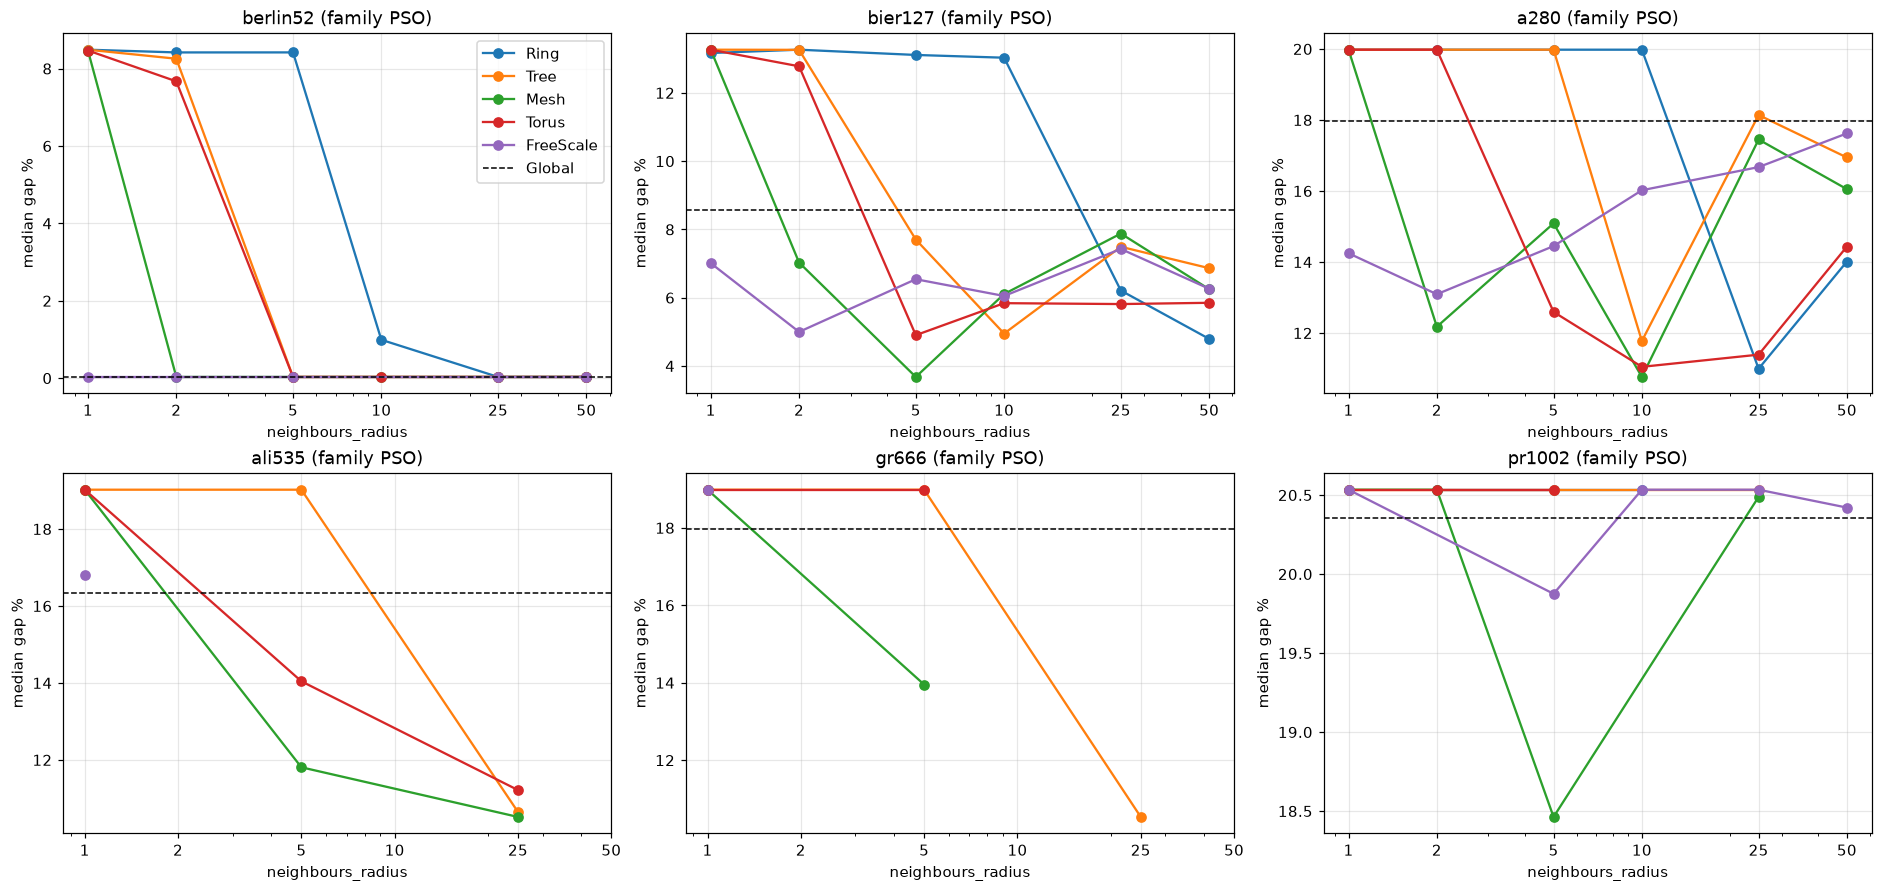

In [8]:
fig, axes = plt.subplots(2, 3, figsize=(17, 8), constrained_layout=True)
for ax, prob in zip(axes.flat, PROBLEMS):
    sub = runs[(runs.problem == prob) & runs.topology.isin(STATIC) & (runs.family == "PSO")]
    for topo in STATIC:
        s = sub[sub.topology == topo].groupby("radius").gap.median()
        ax.plot(s.index, s.values, marker="o", label=topo)
    g = cfg[(cfg.problem == prob) & (cfg.family == "PSO") & (cfg.topology == "Global")].gap_median
    if len(g):
        ax.axhline(g.iloc[0], color="k", ls="--", lw=1, label="Global")
    ax.set_xscale("log"); ax.set_xticks([1, 2, 5, 10, 25, 50], ["1", "2", "5", "10", "25", "50"])
    ax.set_title(f"{prob} (family PSO)"); ax.set_xlabel("neighbours_radius"); ax.set_ylabel("median gap %")
axes.flat[0].legend()
plt.show()

In [9]:
print("Median gap % by radius, pooled over static topologies, per family")
rad = runs[runs.topology.isin(STATIC)]
rad.pivot_table(index=["problem", "family"], columns="radius", values="gap",
                aggfunc="median", observed=True).style.format("{:.2f}", na_rep="–")

Median gap % by radius, pooled over static topologies, per family


### 3.2 Dynamic similarity topologies

In [10]:
dyn = cfg[cfg.topology.isin(DYNAMIC)]
dyn.pivot_table(index=["problem", "family"], columns=["topology", "param"],
                values="gap_median", observed=True).style.format("{:.2f}", na_rep="–") \
   .background_gradient(axis=1, cmap="RdYlGn_r")

### 3.3 APV / SWU probe after the fix

This is the parameter probe from group `APVX`: `v_max = 2`, with an exploration term `v_explore` ∈ {0, 0.5, 1}. Here 0 is the operator as published.

In [11]:
apv = cfg[cfg.family.isin(["PSO-APV", "PSO-SWU"])]
t = apv.pivot_table(index="problem", columns=["family", "param"], values="gap_median", observed=True)
t.insert(0, "greedy start", runs.groupby("problem", observed=True).init_gap.median().reindex(t.index))
t.style.format("{:.2f}", na_rep="–")

## 4. Distributions: the best configurations next to the baselines

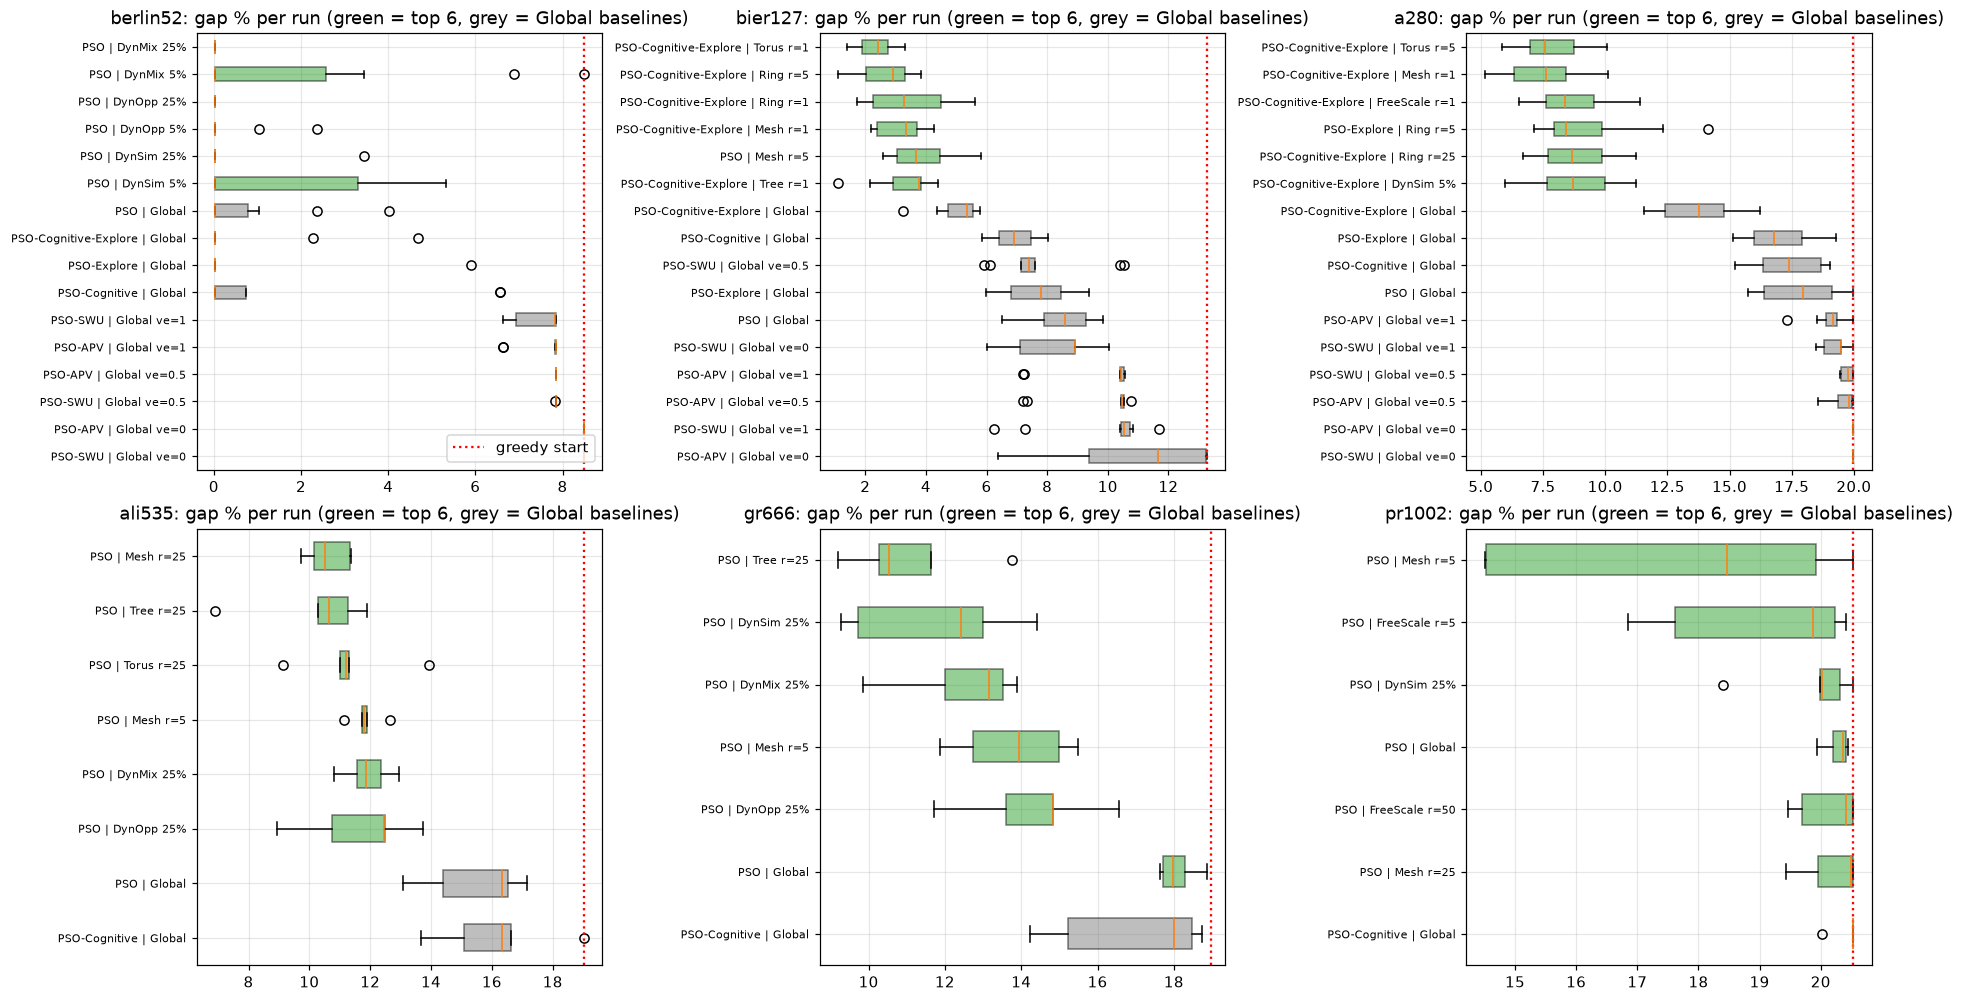

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
for ax, prob in zip(axes.flat, PROBLEMS):
    c = cfg[cfg.problem == prob]
    top = list(c.nsmallest(6, "gap_median").config)
    base = [x for x in c[c.topology == "Global"].sort_values("gap_median").config if x not in top]
    order = top + base
    data = [runs[(runs.problem == prob) & (runs.config == x)].gap.values for x in order]
    bp = ax.boxplot(data, orientation="horizontal", patch_artist=True)
    for i, patch in enumerate(bp["boxes"]):
        patch.set_facecolor("tab:green" if i < len(top) else "tab:gray"); patch.set_alpha(0.5)
    ax.set_yticks(range(1, len(order) + 1), order, fontsize=7)
    ax.invert_yaxis()
    ax.axvline(runs[runs.problem == prob].init_gap.median(), color="r", ls=":", label="greedy start")
    ax.set_title(f"{prob}: gap % per run (green = top 6, grey = Global baselines)")
axes.flat[0].legend(loc="lower right")
plt.show()

## 5. Statistical comparison

**Friedman test across instances.** Each *block* is one instance. Each *treatment* is a (family, topology) pair at its best parameter, restricted to pairs measured on all six instances. Average ranks are shown first (lower is better), then the Nemenyi post-hoc test.

In [13]:
fams_ft = ["PSO", "PSO-Cognitive", "PSO-Explore", "PSO-Cognitive-Explore"]
block = (cfg[cfg.family.isin(fams_ft)]
            .assign(treat=lambda d: d.family + " | " + d.topology)
            .groupby(["problem", "treat"], observed=True).gap_median.min().unstack())
block = block.dropna(axis=1)
print(f"{block.shape[1]} treatments measured on all {block.shape[0]} instances")
stat, p = ss.friedmanchisquare(*[block[c] for c in block.columns])
print(f"Friedman chi2 = {stat:.2f}, p = {p:.3g}")
ranks = block.rank(axis=1).mean().sort_values()
ranks.to_frame("avg rank").T

16 treatments measured on all 6 instances
Friedman chi2 = 59.62, p = 2.93e-07


treat,PSO | Mesh,PSO | Tree,PSO | DynSim,PSO | Torus,PSO | FreeScale,PSO | DynMix,PSO | Global,PSO | DynOpp,PSO-Cognitive | Global,PSO-Cognitive | FreeScale,PSO-Cognitive | Mesh,PSO-Cognitive | Tree,PSO-Cognitive | Torus,PSO-Cognitive | DynOpp,PSO-Cognitive | DynSim,PSO-Cognitive | DynMix
avg rank,2.17,4.08,4.33,5.75,6.0,6.92,7.17,7.42,8.33,9.75,10.5,10.92,12.58,13.08,13.08,13.92


In [14]:
nem = sp.posthoc_nemenyi_friedman(block.reset_index(drop=True))
top_t = list(ranks.index[:8])
print("Nemenyi p-values among the 8 best-ranked treatments")
nem.loc[top_t, top_t].style.format("{:.3f}").map(lambda v: "font-weight: bold" if v < 0.05 else "")

Nemenyi p-values among the 8 best-ranked treatments


,PSO | Mesh,PSO | Tree,PSO | DynSim,PSO | Torus,PSO | FreeScale,PSO | DynMix,PSO | Global,PSO | DynOpp
PSO | Mesh,1.000,1.000,1.000,0.996,0.992,0.940,0.910,0.872
PSO | Tree,1.000,1.000,1.000,1.000,1.000,1.000,0.999,0.998
PSO | DynSim,1.000,1.000,1.000,1.000,1.000,1.000,1.000,0.999
PSO | Torus,0.996,1.000,1.000,1.000,1.000,1.000,1.000,1.000
PSO | FreeScale,0.992,1.000,1.000,1.000,1.000,1.000,1.000,1.000
PSO | DynMix,0.940,1.000,1.000,1.000,1.000,1.000,1.000,1.000
PSO | Global,0.910,0.999,1.000,1.000,1.000,1.000,1.000,1.000
PSO | DynOpp,0.872,0.998,0.999,1.000,1.000,1.000,1.000,1.000


**The three small instances, with the Explore families included.** These families were only re-run after fix `0b2f1e5`, and so far only on berlin52, bier127 and a280. Three blocks give a weak test, so read the average ranks rather than the p-value.

In [15]:
fams_small = ["PSO", "PSO-Cognitive", "PSO-Explore", "PSO-Cognitive-Explore"]
small = ["berlin52", "bier127", "a280"]
block_s = (cfg[cfg.family.isin(fams_small) & cfg.problem.isin(small)]
              .assign(treat=lambda d: d.family + " | " + d.topology)
              .groupby(["problem", "treat"], observed=True).gap_median.min().unstack()
              .dropna(axis=1))
stat, p = ss.friedmanchisquare(*[block_s[c] for c in block_s.columns])
print(f"{block_s.shape[1]} treatments on {block_s.shape[0]} instances: Friedman chi2 = {stat:.2f}, p = {p:.3g}")
ranks_s = block_s.rank(axis=1).mean().sort_values()
ranks_s.to_frame("avg rank").T

36 treatments on 3 instances: Friedman chi2 = 86.88, p = 2.67e-06


treat,PSO-Cognitive-Explore | Torus,PSO-Cognitive-Explore | Mesh,PSO-Cognitive-Explore | Ring,PSO-Cognitive-Explore | FreeScale,PSO-Cognitive-Explore | Tree,PSO | Mesh,PSO-Cognitive-Explore | DynMix,PSO-Cognitive-Explore | DynSim,PSO-Explore | Tree,PSO-Explore | Ring,...,PSO | DynOpp,PSO | Global,PSO-Cognitive | Global,PSO-Cognitive | Mesh,PSO-Cognitive | Tree,PSO-Cognitive | Torus,PSO-Cognitive | DynOpp,PSO-Cognitive | DynSim,PSO-Cognitive | Ring,PSO-Cognitive | DynMix
avg rank,5.5,6.5,7.17,8.17,8.83,10.17,10.5,10.83,11.17,11.83,...,23.5,24.5,26.83,29.17,29.67,32.0,33.0,34.0,34.33,35.0


In [16]:
print("Average rank per family (pooled over topologies, small instances)")
ranks_s.groupby(lambda t: t.split(" | ")[0]).mean().sort_values().to_frame("avg rank").T

Average rank per family (pooled over topologies, small instances)


treat,PSO-Cognitive-Explore,PSO-Explore,PSO,PSO-Cognitive
avg rank,9.87,15.2,18.09,30.83


**Per instance:** a Kruskal-Wallis test over the runs of each family's best configuration checks whether the families differ on a single instance. With 5–10 runs per configuration the test has low power, so treat it as indicative only.

In [17]:
res = []
for prob in PROBLEMS:
    bf = best_per_family[best_per_family.problem == prob]
    groups = [runs[(runs.problem == prob) & (runs.config == c)].gap.values for c in bf.config]
    groups = [g for g in groups if len(g) > 1]
    if len(groups) > 1:
        h, p = ss.kruskal(*groups)
        res.append(dict(problem=prob, families=len(groups), H=h, p=p))
pd.DataFrame(res)

,problem,families,H,p
0,berlin52,6,48.06,3.46e-09
1,bier127,6,51.05,8.43e-10
2,a280,6,46.28,7.97e-09
3,ali535,2,6.82,9.02e-03
4,gr666,2,6.82,9.02e-03
5,pr1002,2,5.54,1.86e-02


## 6. Time

The wall times come from SLURM nodes that may differ in hardware, so compare times **within an instance**, not across batches run weeks apart. Runs stop early after `stagnation_window` iterations without improvement, which is why *iterations run* and *seconds per iteration* are also shown.

In [18]:
tt = runs.pivot_table(index="problem", columns="family", values="wall", aggfunc="median", observed=True) / 60
tt = tt.reindex(columns=[f for f in FAMILIES if f in tt.columns])
print("Median wall time per run [minutes]")
tt.style.format("{:.1f}", na_rep="–").background_gradient(axis=1, cmap="Oranges")

Median wall time per run [minutes]


family,PSO,PSO-Cognitive,PSO-Explore,PSO-Cognitive-Explore,PSO-APV,PSO-SWU
problem,,,,,,
berlin52,4.4,15.6,4.7,7.1,0.7,0.6
bier127,13.6,20.0,15.5,30.5,5.0,5.0
a280,29.5,37.2,48.5,91.4,7.2,7.2
ali535,163.3,102.8,–,–,–,–
gr666,126.1,138.4,–,–,–,–
pr1002,150.3,268.4,–,–,–,–


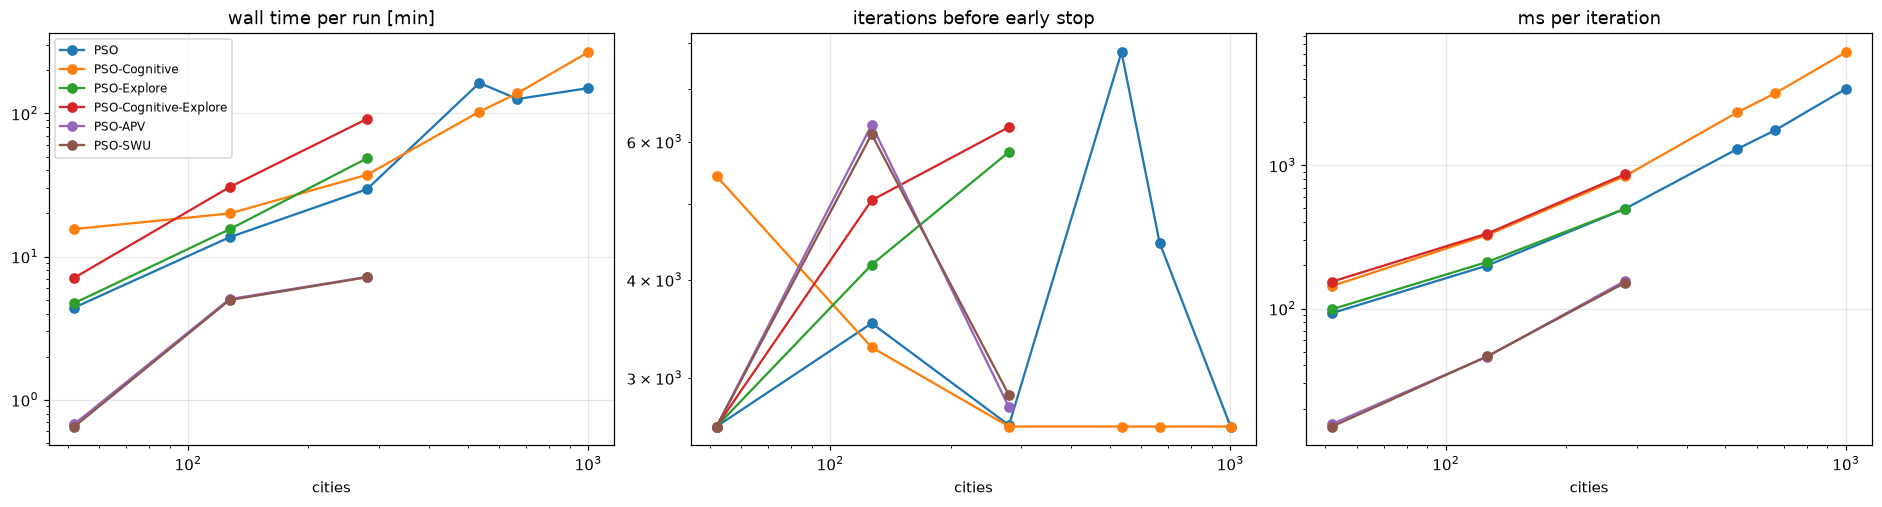

,family,instances,exponent_k
0,PSO,6,1.31
1,PSO-Cognitive,6,0.98
2,PSO-Explore,3,1.38
3,PSO-Cognitive-Explore,3,1.52
4,PSO-APV,3,1.42
5,PSO-SWU,3,1.44


In [19]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), constrained_layout=True)
for fam in FAMILIES:
    s = runs[runs.family == fam].groupby("dim")
    if not len(s):
        continue
    axes[0].plot(s.wall.median().index, s.wall.median().values / 60, marker="o", label=fam)
    axes[1].plot(s.iterations.median().index, s.iterations.median().values, marker="o", label=fam)
    axes[2].plot(s.sec_per_iter.median().index, s.sec_per_iter.median().values * 1000, marker="o", label=fam)
for ax, t in zip(axes, ["wall time per run [min]", "iterations before early stop", "ms per iteration"]):
    ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("cities"); ax.set_title(t)
axes[0].legend(fontsize=8)
plt.show()

# Empirical scaling exponent: wall ~ n^k, fitted on per-family medians.
fit = []
for fam in FAMILIES:
    s = runs[runs.family == fam].groupby("dim").wall.median()
    if len(s) >= 3:
        k, _ = np.polyfit(np.log(s.index), np.log(s.values), 1)
        fit.append(dict(family=fam, instances=len(s), exponent_k=k))
pd.DataFrame(fit)

In [20]:
print("Median wall time per run [min] by topology (all non-APV families pooled)")
(runs[~runs.family.isin(["PSO-APV", "PSO-SWU"])]
    .pivot_table(index="problem", columns="topology", values="wall", aggfunc="median", observed=True)
    .reindex(columns=["Global"] + STATIC + DYNAMIC) / 60).style.format("{:.1f}", na_rep="–") \
    .background_gradient(axis=1, cmap="Oranges")

Median wall time per run [min] by topology (all non-APV families pooled)


topology,Global,Ring,Tree,Mesh,Torus,FreeScale,DynSim,DynOpp,DynMix
problem,,,,,,,,,
berlin52,5.5,5.4,10.2,5.7,7.7,90.9,6.5,6.4,6.3
bier127,17.4,14.1,25.0,15.8,20.7,96.7,18.2,18.2,15.9
a280,38.4,35.2,39.3,40.9,39.7,117.3,44.1,37.2,38.2
ali535,232.8,–,99.8,99.7,102.0,182.9,178.1,102.4,103.0
gr666,160.1,–,152.3,134.8,134.5,218.3,293.8,148.4,139.1
pr1002,175.5,150.0,158.0,264.5,151.2,303.1,268.4,209.7,213.3


In [21]:
print("Median iterations run before early stop (max_iter = 30000)")
print(runs.pivot_table(index="problem", columns="family", values="iterations", aggfunc="median",
                       observed=True).reindex(columns=FAMILIES).to_string(na_rep="-"))
print(f"\nRuns that reached the 30000-iteration cap: {(runs.iterations >= 30000).sum()} of {len(runs)}")
print("\nMedian milliseconds per iteration, by topology")
(runs.pivot_table(index="problem", columns="topology", values="sec_per_iter", aggfunc="median", observed=True)
     .reindex(columns=["Global"] + STATIC + DYNAMIC) * 1000).style.format("{:.0f}", na_rep="–") \
     .background_gradient(axis=1, cmap="Oranges")

Median iterations run before early stop (max_iter = 30000)
family       PSO  PSO-Cognitive  PSO-Explore  PSO-Cognitive-Explore  PSO-APV  PSO-SWU
problem                                                                              
berlin52  2601.0         5421.0       2601.0                 2601.0   2601.0   2601.0
bier127   3521.0         3281.0       4181.0                 5051.0   6301.0   6131.0
a280      2611.0         2601.0       5821.0                 6261.0   2751.0   2851.0
ali535    7801.0         2601.0            -                      -        -        -
gr666     4461.0         2601.0            -                      -        -        -
pr1002    2601.0         2601.0            -                      -        -        -

Runs that reached the 30000-iteration cap: 0 of 4165

Median milliseconds per iteration, by topology


topology,Global,Ring,Tree,Mesh,Torus,FreeScale,DynSim,DynOpp,DynMix
problem,,,,,,,,,
berlin52,20,111,141,117,153,1979,130,130,127
bier127,55,193,310,257,313,2059,279,278,279
a280,164,490,833,659,674,2324,693,527,694
ali535,1756,–,1976,1787,1833,3265,1335,1327,1317
gr666,2362,–,1925,2430,3103,4079,2479,2475,2494
pr1002,3192,3460,3635,4765,3487,5185,6191,4838,4793


### 6.1 Quality vs time trade-off

Each dot is one configuration. The line is the Pareto front: no other configuration is both faster *and* better.

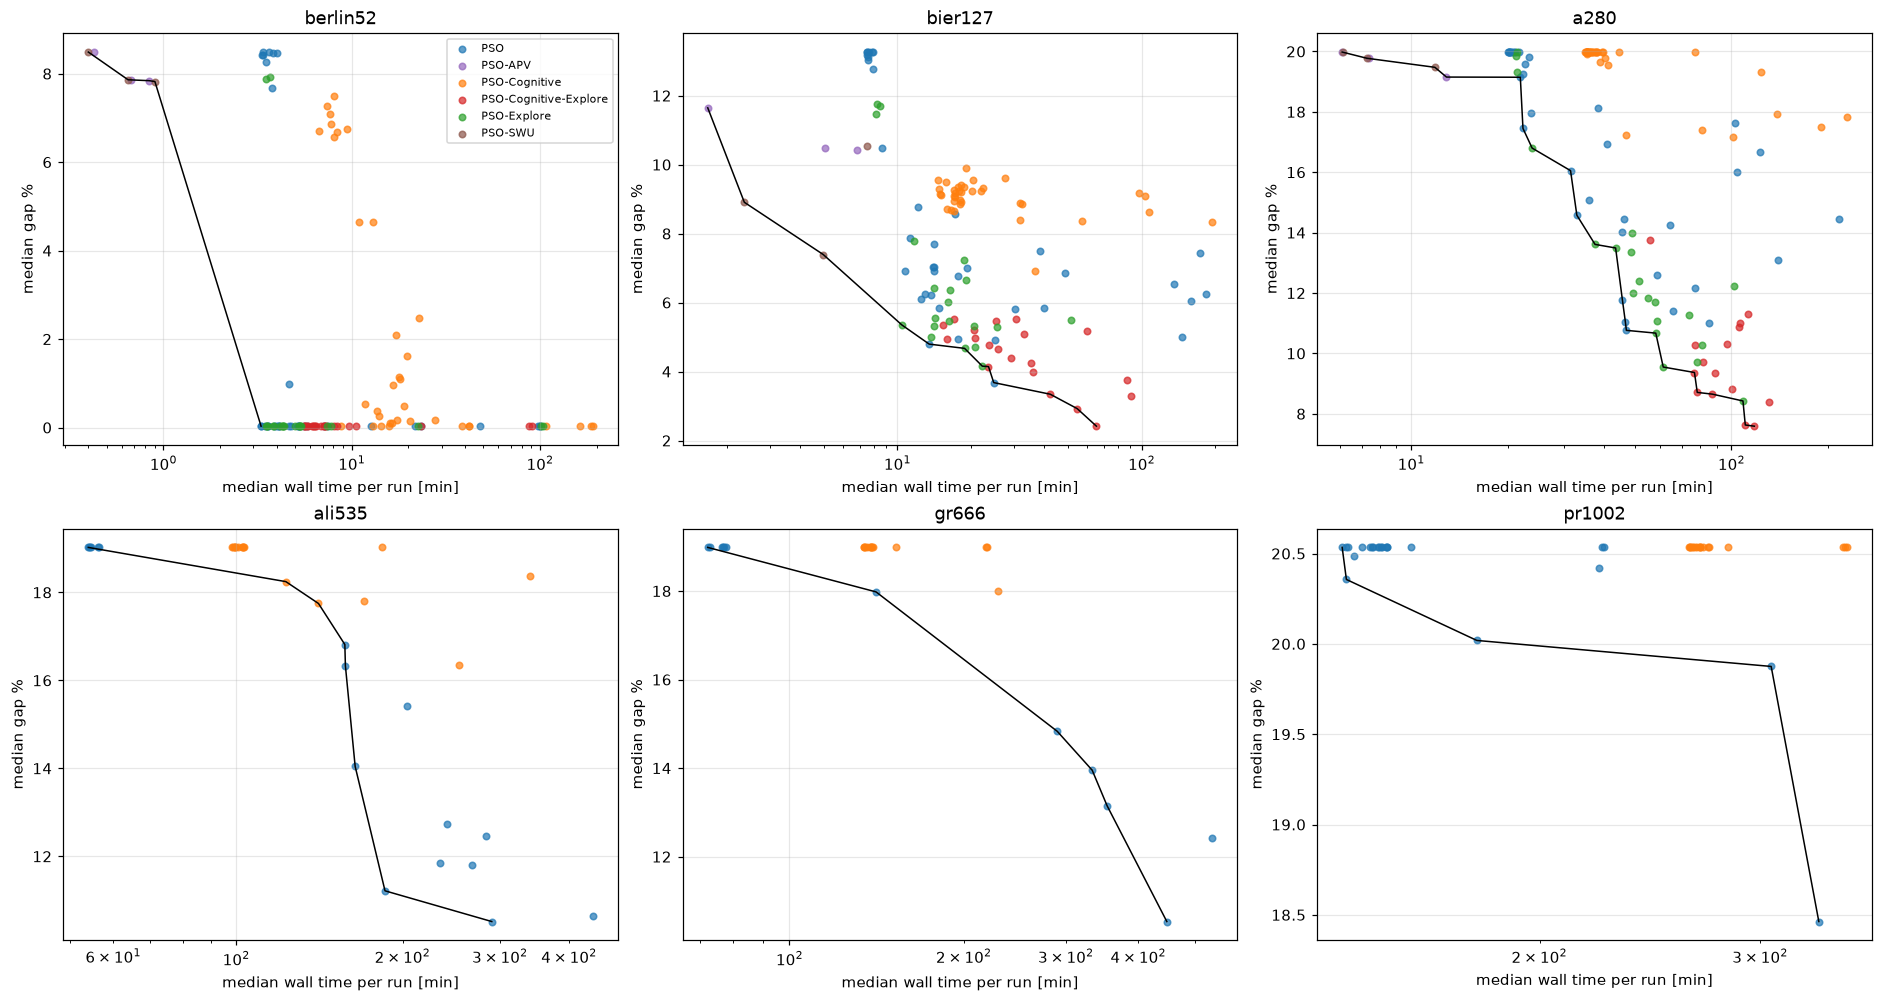

,problem,config,gap_median,wall_min
0,berlin52,PSO-SWU | Global ve=0,8.49,0.40
1,berlin52,PSO-SWU | Global ve=0.5,7.86,0.65
2,berlin52,PSO-APV | Global ve=1,7.84,0.84
3,berlin52,PSO-SWU | Global ve=1,7.82,0.90
4,berlin52,PSO | Global,0.03,3.30
5,bier127,PSO-APV | Global ve=0,11.65,1.67
6,bier127,PSO-SWU | Global ve=0,8.91,2.36
7,bier127,PSO-SWU | Global ve=0.5,7.39,4.97
8,bier127,PSO-Explore | Mesh r=5,5.35,10.43
9,bier127,PSO | Ring r=50,4.79,13.49


In [22]:
colors = dict(zip(FAMILIES, plt.cm.tab10.colors))
fig, axes = plt.subplots(2, 3, figsize=(17, 9), constrained_layout=True)
pareto_rows = []
for ax, prob in zip(axes.flat, PROBLEMS):
    c = cfg[cfg.problem == prob].sort_values("wall_median")
    for fam, g in c.groupby("family"):
        ax.scatter(g.wall_median / 60, g.gap_median, s=18, alpha=0.7, color=colors[fam], label=fam)
    front, best = [], np.inf
    for _, r in c.iterrows():
        if r.gap_median < best:
            best = r.gap_median; front.append(r)
    front = pd.DataFrame(front)
    ax.plot(front.wall_median / 60, front.gap_median, "k-", lw=1)
    pareto_rows.append(front.assign(problem=prob))
    ax.set_xscale("log"); ax.set_xlabel("median wall time per run [min]"); ax.set_ylabel("median gap %")
    ax.set_title(prob)
axes.flat[0].legend(fontsize=7)
plt.show()
pareto = pd.concat(pareto_rows)[["problem", "config", "gap_median", "wall_median"]]
pareto.assign(wall_min=pareto.wall_median / 60).drop(columns="wall_median").reset_index(drop=True)

## 7. Convergence

`iteration_history` stores the global best every 20 iterations. Curves are the median across runs, with runs that stopped early padded with their final value. Shown are the Global-topology variants plus the best configuration on each instance.

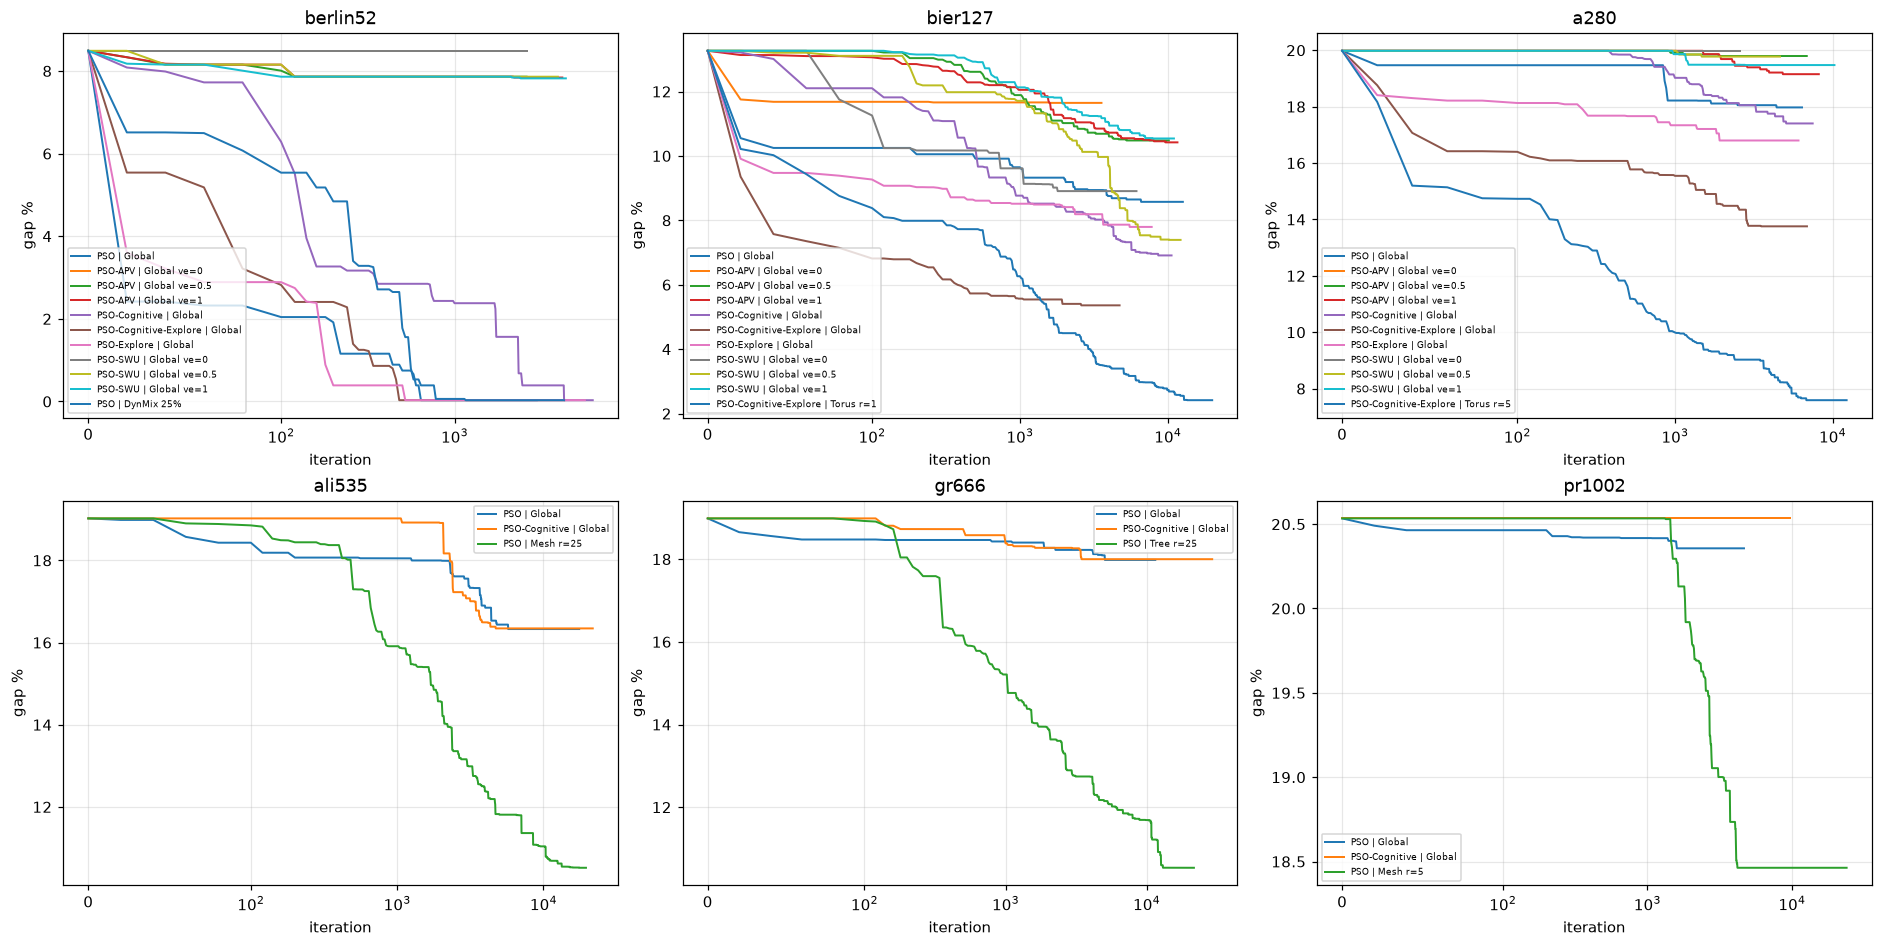

In [23]:
def median_curve(hist):
    L = max(len(h) for h in hist)
    M = np.vstack([np.pad(h, (0, L - len(h)), mode="edge") for h in hist])
    return np.arange(L) * 20, np.median(M, axis=0)

fig, axes = plt.subplots(2, 3, figsize=(17, 8.5), constrained_layout=True)
for ax, prob in zip(axes.flat, PROBLEMS):
    c = cfg[cfg.problem == prob]
    show = list(c[c.topology == "Global"].config) + [c.nsmallest(1, "gap_median").config.iloc[0]]
    for x in dict.fromkeys(show):
        sub = runs[(runs.problem == prob) & (runs.config == x)]
        it, med = median_curve(list(sub.history))
        ax.plot(it, (med - OPTIMA[prob]) / OPTIMA[prob] * 100, label=x, lw=1.3)
    ax.set_xscale("symlog", linthresh=100); ax.set_xlabel("iteration"); ax.set_ylabel("gap %")
    ax.set_title(prob); ax.legend(fontsize=6)
plt.show()

## 8. Conclusions

*Based on 4165 valid runs in 451 configurations. These numbers reflect `results/` as of 2026-10-20; re-run the notebook after new results arrive.*

### Data validity
* **About 60 % of the result files can't be used.** 351 APV/SWU files were made before fix `38e0dcb`, 242 Explore files before fix `0b2f1e5`, and 103 ali535/gr666 files with the GEO distance bug. They must not be pooled with anything.
* After filtering, coverage is lopsided. The Explore families exist only on the three small instances, and APV/SWU only as the 3-instance probe. **Any claim about large instances is a claim about PSO and PSO-Cognitive only.** The pending design-C runs on ali535, gr666 and pr1002 are what will close that gap.

### Quality
1. **Every variant solves berlin52.** Dozens of configurations reach the optimal tour (0.03 %, the float-vs-integer rounding offset), so berlin52 doesn't separate the algorithms. Use it only as a sanity check.
2. **PSO-Cognitive-Explore is the best family wherever it was run.** On bier127 its median gap is 2.42 % (Torus r=1), against 3.68 % for the best plain PSO. On a280 it is 7.59 % (Torus r=5) against 10.76 %. On the three small instances its average Friedman rank is 9.9, against 15.2 for PSO-Explore, 18.1 for PSO and 30.8 for PSO-Cognitive. The top five treatments are all Cognitive-Explore with static topologies.
3. **The cognitive step on its own hurts, and only pays off together with Explore.** PSO-Cognitive is the worst non-APV family on every instance. From a280 upwards its best median equals the greedy start exactly (19.98 % on a280, 20.53 % on pr1002), so it never improves on its initial tour. Pulling toward the personal best speeds up convergence onto the start tour. Explore's perturbation is what keeps it from locking there.
4. **Local topologies beat Global, but the radius matters more than the shape.** r=1 is consistently the worst for plain PSO. From r=5 the curve is flat on the small instances, and the larger instances want r=25 (ali535: Mesh r=25 10.5 %, gr666: Tree r=25 10.5 %, against Global 16.3 % / 18.0 %). Explore inverts this: Cognitive-Explore is best at **r=1** on bier127 and a280, because the perturbation already supplies diversity and the tight neighbourhood adds exploitation. Mesh/Torus at equal radius see far more neighbours than Ring ($(2r+1)^2-1$ vs $2r$), so "topology" and "neighbourhood size" are still confounded.
5. **Topology differences within PSO aren't statistically significant.** The Friedman test over 6 instances is significant (p ≈ 3e-7), but Nemenyi finds no significant pair among the eight PSO topologies (all p > 0.87). The significance comes from PSO vs PSO-Cognitive. Six blocks with 5–10 runs each is too little power to rank topologies. Mesh has the best average rank (2.2), which hints that it may be the strongest topology, but the tests don't support claiming it is better.
6. **The dynamic similarity topologies are mid-pack.** None of them is the best on any instance above berlin52. Their best result is DynSim 5 % on a280 (14.6 %, still worse than static Mesh r=10). 25 % neighbourhoods generally beat 5 % on the larger instances. DynMix brings no consistent gain over DynSim or DynOpp.
7. **APV/SWU are still not competitive after the fix.** With `v_explore=0` (the published operator) they don't move from the greedy start on berlin52 and a280. With `v_explore` ∈ {0.5, 1} they gain only 0.6–0.8 pp on berlin52/a280 and up to 5.9 pp with SWU on bier127. That still leaves them far behind the OX-based variants.
8. **pr1002 is essentially unsolved.** The best median is 18.5 % (PSO Mesh r=5) against a 20.5 % greedy start. Most configurations improve the start by < 0.5 %.

### Time
1. **No run used its iteration budget.** None of the 4165 runs reached `max_iter = 30000`. The median is 2601 iterations, the early-stop floor, even on pr1002. **The stopping rule decides the result, not the budget.** On the large instances PSO stops after ~2600 iterations having barely moved. Before drawing conclusions about large instances, test a longer `stagnation_window` or patience scaled with $n$.
2. **The Explore families are 1.5–3× slower, and they are slower because they keep improving.** On a280 the median is 48 min (Explore) and 91 min (Cognitive-Explore) against 30 min for PSO. Explore adds no per-iteration cost (a280: 0.50 s for PSO and PSO-Explore; 0.84 s for Cognitive and 0.87 s for Cognitive-Explore, because the cognitive step adds a second crossover). They run more iterations (5.8k–6.3k vs 2.6k) because they keep finding improvements.
3. **FreeScale has an implementation cost problem.** On berlin52 it costs ~1980 ms per iteration, against 110–150 ms for the other local topologies and 20 ms for Global, so FreeScale runs take 90+ min where the others take ~6 min. The topology isn't more expensive in principle, so its neighbourhood-best lookup is the first thing to profile or JIT.
4. **Local topologies cost ~6× per iteration over Global** (berlin52: ~120 vs 20 ms). That is the Python per-particle neighbourhood lookup, the next candidate for Numba after `path_length()`.
5. **APV/SWU are the fastest per iteration** (Numba-parallel, ~3–4× cheaper than OX on a280). For now the speed is wasted, since they barely improve on the greedy start.
6. Wall time grows roughly as $n^{1.0\text{–}1.5}$ per run. The exponent is flattened by early stopping, which caps the iteration count; per-iteration cost grows close to linearly in $n$.

### Quality vs time
* On bier127, **PSO Mesh r=5** is the efficient choice: 3.7 % in 25 min. Cognitive-Explore Torus r=1 buys the last 1.3 pp for 2.6× the time (65 min).
* On a280 there is no cheap shortcut. Each extra point of gap costs time, up to Cognitive-Explore Torus r=5 (7.6 %, ~2 h per run).

### Next steps
1. Finish the design-C runs on ali535, gr666 and pr1002 for both Explore families. That is the experiment that can confirm conclusion 2 at scale.
2. Re-test the early-stop rule on a280 and pr1002 with a longer patience.
3. Profile and JIT the FreeScale and other local-topology neighbourhood lookups.
4. Compare topologies at **equal neighbourhood size** rather than equal radius, to separate the effect of topology shape from neighbourhood size.
5. Use more runs (≥ 20) on the instances where configurations differ by < 1 pp, so that topology differences can reach significance.